<a href="https://colab.research.google.com/github/haydencase0/MachineLearning/blob/main/notebooks/starter_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import polars as pl
import polars.selectors as cs
import seaborn as sns
import numpy as np
from plotnine import ggplot, aes, geom_col, theme_minimal, labs
from pathlib import Path
from xgboost import XGBRegressor
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

In [3]:
housing = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing.csv')

quantifiable evidence that the predictions we come up with are reliable

which property types are weighing most heavily in the house prices predicted by your model.

is if there are additional factors about these areas that might be affecting prices, which we aren't taking into account.

In [4]:
features_df = housing.drop(["id", "date", "price"])

cat_cols = [col for col, dtype in zip(features_df.columns, features_df.dtypes) if dtype == pl.Utf8]
if len(cat_cols) > 0:
    features_df = features_df.to_dummies(columns=cat_cols)
else:
    features_df = features_df.to_dummies()

median_price = housing["price"].median()
target = (housing["price"] > median_price).cast(pl.Int32).to_numpy()

X = features_df.to_numpy()
y = target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
clf.fit(X_train, y_train)

accuracy = clf.score(X_test, y_test)
print(f"Classifier Accuracy: {accuracy:.4f}")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:09:07] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.



Classifier Accuracy: 0.8845


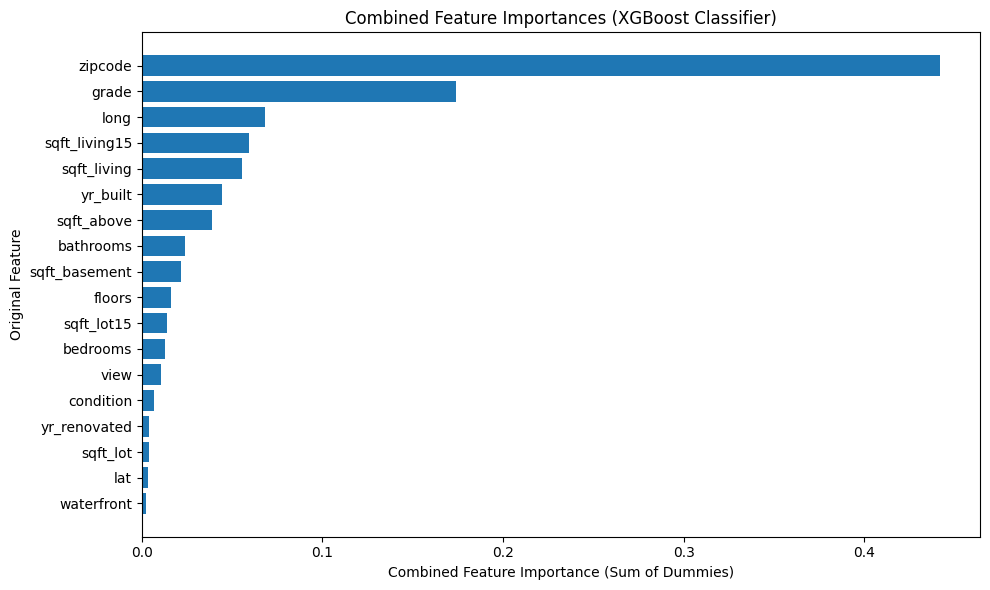

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import re

# Get feature importances from our trained classifier
importances = clf.feature_importances_
feature_names = features_df.columns

# Create a DataFrame for individual dummy importances
feat_imp_df = pd.DataFrame({
    'Dummy_Feature': feature_names,
    'Importance': importances
})

# Map each dummy column back to its original column name
# Since Polars to_dummies creates columns like 'column_value', we map them back
original_columns = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                    "waterfront", "view", "condition", "grade", "sqft_above",
                    "sqft_basement", "yr_built", "yr_renovated", "zipcode",
                    "lat", "long", "sqft_living15", "sqft_lot15"]

def map_to_original(dummy_name):
    for orig in original_columns:
        if dummy_name.startswith(orig + "_") or dummy_name == orig:
            return orig
    return dummy_name

feat_imp_df['Original_Feature'] = feat_imp_df['Dummy_Feature'].apply(map_to_original)

# Combine (sum) the importances by the original feature name
combined_imp_df = feat_imp_df.groupby('Original_Feature')['Importance'].sum().reset_index()
combined_imp_df = combined_imp_df.sort_values(by='Importance', ascending=False)

# Plot the combined feature importances
plt.figure(figsize=(10, 6))
plt.barh(combined_imp_df['Original_Feature'], combined_imp_df['Importance'])
plt.gca().invert_yaxis()
plt.xlabel('Combined Feature Importance (Sum of Dummies)')
plt.ylabel('Original Feature')
plt.title('Combined Feature Importances (XGBoost Classifier)')
plt.tight_layout()
plt.show()